# Пайплайн v2: класифікатор → U-Net з кропів (768) → постобробка

Етап 9, покращення 1, крок 4. Копія `08_pipeline.ipynb` з новою U-Net (`09_unet_crops_train.ipynb`, val Dice 0.7227 на 768);
ймовірності — з `10_inference_768.ipynb` (`data/inference_768_v1/`). Усе локально. Мета — чесне порівняння з v1
за метрикою змагання: **val F2 пайплайну v1 = 0.8491**.

Скор одного знімка при порозі класифікатора **c**:

| насправді | класифікатор | скор |
|---|---|---|
| порожньо | p < c | 1 |
| порожньо | p ≥ c | 1, якщо після постобробки не лишилось жодної компоненти, інакше 0 |
| є кораблі | p < c | 0 |
| є кораблі | p ≥ c | F2 масок U-Net |

Відмінності від `08`:
- U-Net рахувалась лише для знімків з p ≥ 0.5 (+ усі val-знімки з кораблями), тож c перебираємо від 0.5;
  решта знімків за будь-якого такого c відсіюється класифікатором. Рядка «без класифікатора» немає.
- Ймовірності вже 768×768 — без збільшення.
- Пороги U-Net ширші (0.3–0.8): нова модель може давати ймовірності іншого масштабу.

## 1. Дані

In [1]:
import sys
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from dataset import rles_by_image
from metric import IOU_THRESHOLDS, f2_dataset
from postprocess import mask_to_rles
from rle import IMAGE_SHAPE, rle_decode

DATA_DIR = ROOT / "data"
INFERENCE_DIR = DATA_DIR / "inference_768_v1"
OUT_DIR = DATA_DIR / "pipeline_768_v1"
OUT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 42
CONNECTIVITY = 4
CLASSIFIER_MIN_P = 0.5
V1_F2 = 0.8491

masks = pd.read_csv(DATA_DIR / "train_ship_segmentations_v2.csv")
rles = rles_by_image(masks)


def attach_unet(table, npz_path):
    # Номер знімка в масиві ймовірностей або −1, якщо U-Net його не рахувала.
    npz = np.load(npz_path, allow_pickle=True)
    position = {image_id: i for i, image_id in enumerate(npz["image_ids"])}
    table["unet_index"] = table["ImageId"].map(position).fillna(-1).astype(int)
    return npz["probs"]


val = pd.read_csv(DATA_DIR / "classifier_v1" / "val_probs.csv")
val_unet = attach_unet(val, INFERENCE_DIR / "val_unet_probs_768.npz")
test = pd.read_csv(DATA_DIR / "inference_v1" / "test_classifier_probs.csv")
test_unet = attach_unet(test, INFERENCE_DIR / "test_unet_probs_768.npz")

has_ships = (val["n_ships"] > 0).values
assert ((val["unet_index"] >= 0) == ((val["p"] >= CLASSIFIER_MIN_P) | has_ships)).all()
assert ((test["unet_index"] >= 0) == (test["p"] >= CLASSIFIER_MIN_P)).all()
print(f"val: {len(val)} знімків, з кораблями {has_ships.mean():.1%}, з ймовірностями U-Net {(val['unet_index'] >= 0).sum()}")
print(f"test: {len(test)} знімків, з ймовірностями U-Net {(test['unet_index'] >= 0).sum()}")
print(f"ймовірності U-Net: val {val_unet.shape}, test {test_unet.shape}, {(val_unet.nbytes + test_unet.nbytes) / 1e9:.1f} ГБ")

val: 19256 знімків, з кораблями 22.1%, з ймовірностями U-Net 4791
test: 15606 знімків, з ймовірностями U-Net 3413
ймовірності U-Net: val (4791, 768, 768), test (3413, 768, 768), 4.8 ГБ


## 2. Скор кожного val-знімка, якщо він дійшов до U-Net

Ті самі функції, що в `08`. Для знімків без ймовірностей U-Net скор не визначений (NaN) — у розділі 3 перевіряємо,
що жоден такий знімок не проходить класифікатор.

Прискорення: якщо найбільша ймовірність на знімку ≤ найменшого порогу, компонент не буде за жодного порогу.

In [2]:
def ship_labels(image_rles):
    labels = np.zeros(IMAGE_SHAPE, dtype=np.int32)
    for i, rle in enumerate(image_rles, start=1):
        labels[rle_decode(rle) == 1] = i
    return labels, len(image_rles)


def ious_from_labels(true_labels, n_true, pred_labels, n_pred):
    pairs = true_labels.astype(np.int64) * (n_pred + 1) + pred_labels
    joint = np.bincount(pairs.ravel(), minlength=(n_true + 1) * (n_pred + 1)).reshape(n_true + 1, n_pred + 1)
    intersection = joint[1:, 1:]
    true_areas = joint[1:, :].sum(axis=1)
    pred_areas = joint[:, 1:].sum(axis=0)
    return intersection / (true_areas[:, None] + pred_areas[None, :] - intersection)


def f2_from_ious(ious):
    n_true, n_pred = ious.shape
    if n_true == 0 and n_pred == 0:
        return 1.0
    scores = []
    for threshold in IOU_THRESHOLDS:
        tp = (ious > threshold).any(axis=1).sum()
        scores.append(5 * tp / (5 * tp + 4 * (n_true - tp) + (n_pred - tp)))
    return np.mean(scores)

In [3]:
UNET_THRESHOLDS = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
MIN_AREAS = [0, 20, 40, 80, 150, 300]

start = time.time()
unet_scores = np.full((len(val), len(UNET_THRESHOLDS), len(MIN_AREAS)), np.nan, dtype=np.float32)
for i, (image_id, k) in enumerate(zip(val["ImageId"], val["unet_index"])):
    if k < 0:
        continue
    image_rles = rles.get(image_id, [])
    probs = val_unet[k] / 255
    if probs.max() <= UNET_THRESHOLDS[0]:
        unet_scores[i] = 0.0 if image_rles else 1.0
        continue
    true_labels, n_true = ship_labels(image_rles)
    for t, threshold in enumerate(UNET_THRESHOLDS):
        mask = (probs > threshold).astype(np.uint8)
        n_labels, pred_labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=CONNECTIVITY)
        ious = ious_from_labels(true_labels, n_true, pred_labels, n_labels - 1)
        areas = stats[1:, cv2.CC_STAT_AREA]
        for a, min_area in enumerate(MIN_AREAS):
            unet_scores[i, t, a] = f2_from_ious(ious[:, areas >= min_area])
    if (i + 1) % 5000 == 0:
        print(f"{i + 1} знімків, {time.time() - start:.0f} с")
print(f"готово: {time.time() - start:.0f} с")

15000 знімків, 85 с


готово: 110 с


## 3. Перебір порогу класифікатора

Для кожного c скор знімка — один з трьох варіантів (таблиця вгорі), середнє по всій val. Для порівняння:
**ідеальний класифікатор** (U-Net рівно на знімках з кораблями) — стеля для цієї U-Net і постобробки, і v1.

In [4]:
CLASSIFIER_THRESHOLDS = np.round(np.arange(CLASSIFIER_MIN_P, 1.0, 0.05), 2)
skipped_score = np.where(has_ships, 0.0, 1.0)[:, None, None]


def pipeline_f2(passed):
    scores = np.where(passed[:, None, None], unet_scores, skipped_score)
    assert not np.isnan(scores).any(), "знімок без ймовірностей U-Net пройшов класифікатор"
    return scores.mean(axis=0)


rows = []
for c in CLASSIFIER_THRESHOLDS:
    f2 = pipeline_f2(val["p"].values >= c)
    for t, threshold in enumerate(UNET_THRESHOLDS):
        for a, min_area in enumerate(MIN_AREAS):
            rows.append((c, threshold, min_area, f2[t, a]))
grid = pd.DataFrame(rows, columns=["classifier_threshold", "unet_threshold", "min_area", "f2"])
grid.to_csv(OUT_DIR / "val_pipeline_grid.csv", index=False)

best = grid.loc[grid["f2"].idxmax()]
t_best = UNET_THRESHOLDS.index(best["unet_threshold"])
a_best = MIN_AREAS.index(best["min_area"])
ideal_classifier = pipeline_f2(has_ships)[t_best, a_best]

print(f"найкраще: c = {best['classifier_threshold']}, поріг U-Net {best['unet_threshold']}, "
      f"min_area {int(best['min_area'])} → val F2 {best['f2']:.4f}")
print(f"тривіальний сабміт:      0.7790")
print(f"пайплайн v1:             {V1_F2:.4f}")
print(f"ідеальний класифікатор:  {ideal_classifier:.4f}")

найкраще: c = 0.9, поріг U-Net 0.5, min_area 40 → val F2 0.8591
тривіальний сабміт:      0.7790
пайплайн v1:             0.8491
ідеальний класифікатор:  0.8698


In [5]:
for threshold in UNET_THRESHOLDS:
    table = grid[grid["unet_threshold"] == threshold].pivot(index="classifier_threshold", columns="min_area", values="f2")
    print(f"\nпоріг U-Net {threshold} (рядки — поріг класифікатора c, стовпці — min_area):")
    print(table.round(4).to_string())


поріг U-Net 0.3 (рядки — поріг класифікатора c, стовпці — min_area):
min_area                 0       20      40      80      150     300
classifier_threshold                                                
0.50                  0.8481  0.8502  0.8519  0.8538  0.8533  0.8495
0.55                  0.8496  0.8515  0.8531  0.8548  0.8540  0.8500
0.60                  0.8509  0.8527  0.8539  0.8553  0.8541  0.8500
0.65                  0.8514  0.8532  0.8543  0.8554  0.8539  0.8498
0.70                  0.8525  0.8542  0.8553  0.8561  0.8543  0.8500
0.75                  0.8539  0.8555  0.8564  0.8569  0.8547  0.8502
0.80                  0.8554  0.8568  0.8577  0.8578  0.8551  0.8504
0.85                  0.8562  0.8573  0.8581  0.8579  0.8550  0.8502
0.90                  0.8570  0.8580  0.8586  0.8581  0.8548  0.8498
0.95                  0.8563  0.8571  0.8576  0.8567  0.8533  0.8483

поріг U-Net 0.4 (рядки — поріг класифікатора c, стовпці — min_area):
min_area                 0      

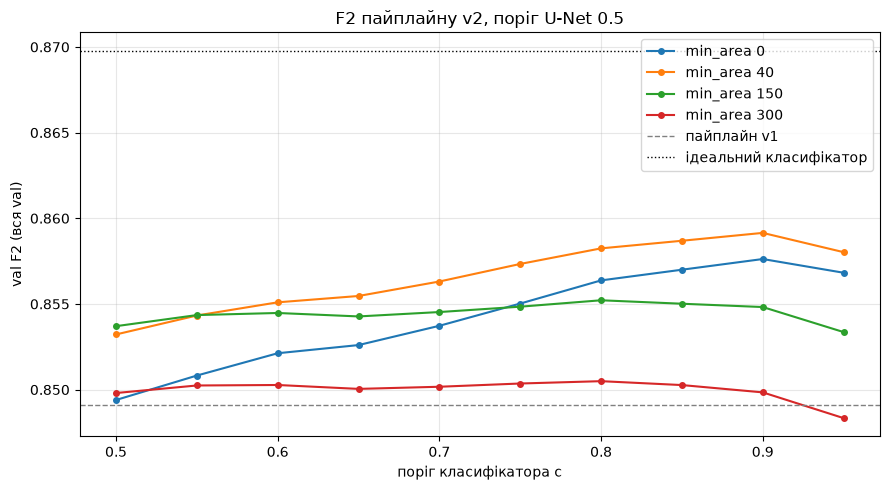

In [6]:
fig, ax = plt.subplots(figsize=(9, 5))
for min_area in [0, 40, 150, 300]:
    curve = grid[(grid["unet_threshold"] == best["unet_threshold"]) & (grid["min_area"] == min_area)]
    ax.plot(curve["classifier_threshold"], curve["f2"], marker="o", markersize=4, label=f"min_area {min_area}")
ax.axhline(V1_F2, color="gray", linestyle="--", linewidth=1, label="пайплайн v1")
ax.axhline(ideal_classifier, color="black", linestyle=":", linewidth=1, label="ідеальний класифікатор")
ax.set_xlabel("поріг класифікатора c")
ax.set_ylabel("val F2 (вся val)")
ax.set_title(f"F2 пайплайну v2, поріг U-Net {best['unet_threshold']}")
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.savefig(OUT_DIR / "val_f2_vs_threshold.png", dpi=80)
plt.show()

### 3.1. Де втрачається скор: v2 проти v1

1 − F2 розкладається на частки втрат (у частках від усієї val):
- **порожні знімки, де лишилась компонента** — FP (false positive, хибна тривога): кожен коштує цілу 1;
- **знімки з кораблями, відсіяні класифікатором** — FN (false negative, пропуск) класифікатора: теж ціла 1;
- **знімки з кораблями, що дійшли до U-Net** — недобрані бали F2 (пропущені кораблі, низький IoU, зайві компоненти).

Покращення 1 змінювало лише U-Net, тож очікуємо зміну передусім у третьому рядку.

In [7]:
V1_LOSSES = [0.005, 0.027, 0.119]

passed = val["p"].values >= best["classifier_threshold"]
final = np.where(passed, unet_scores[:, t_best, a_best], skipped_score[:, 0, 0])
n = len(val)
losses = {
    "порожні знімки з компонентою (FP)": ((~has_ships) & (final == 0)).sum() / n,
    "кораблі, відсіяні класифікатором": (has_ships & ~passed).sum() / n,
    "кораблі, що дійшли до U-Net": (1 - final[has_ships & passed]).sum() / n,
}
print(f"{'':40s} {'v2':>8s} {'v1':>8s}")
for (name, loss), v1_loss in zip(losses.items(), V1_LOSSES):
    print(f"{name:40s} −{loss:.4f}  −{v1_loss:.3f}")
print(f"{'разом':40s} −{sum(losses.values()):.4f}  −{1 - V1_F2:.4f}")
print(f"\nпорожніх знімків з компонентою: {((~has_ships) & (final == 0)).sum()} з {(~has_ships).sum()}; "
      f"відсіяно знімків з кораблями: {(has_ships & ~passed).sum()} з {has_ships.sum()}")
print(f"середній F2 на знімках з кораблями, що дійшли до U-Net: {final[has_ships & passed].mean():.4f}")

                                               v2       v1
порожні знімки з компонентою (FP)        −0.0062  −0.005
кораблі, відсіяні класифікатором         −0.0265  −0.027
кораблі, що дійшли до U-Net              −0.1082  −0.119
разом                                    −0.1409  −0.1509

порожніх знімків з компонентою: 119 з 15000; відсіяно знімків з кораблями: 510 з 4256
середній F2 на знімках з кораблями, що дійшли до U-Net: 0.4439


## 4. Перевірка «повільним» шляхом

Як у `08`: `mask_to_rles` → таблиця формату сабміту → `f2_dataset` з `src/metric.py` на 1 000 випадкових
val-знімках. Скор має збігтися зі швидким підрахунком.

In [8]:
def predict_rows(table, unet_probs):
    rows = []
    for image_id, p, k in zip(table["ImageId"], table["p"], table["unet_index"]):
        image_rles = []
        if p >= best["classifier_threshold"]:
            image_rles = mask_to_rles(unet_probs[k] / 255, threshold=best["unet_threshold"],
                                      min_area=best["min_area"], connectivity=CONNECTIVITY)
        rows += [(image_id, rle) for rle in image_rles] or [(image_id, None)]
    return pd.DataFrame(rows, columns=["ImageId", "EncodedPixels"])


sample = np.random.default_rng(SEED).choice(len(val), size=min(1000, len(val)), replace=False)
sample_ids = val["ImageId"].values[sample]
predicted = predict_rows(val.iloc[sample], val_unet)
slow = f2_dataset(masks[masks["ImageId"].isin(sample_ids)], predicted)
fast = final[sample].mean()
print(f"1000 знімків: швидкий шлях {fast:.4f}, повільний {slow:.4f}")
assert np.isclose(fast, slow)

1000 знімків: швидкий шлях 0.8494, повільний 0.8494


## 5. Сабміт

Ті самі параметри — на test, без жодних змін. Перевірки формату — як у `08`.

In [9]:
start = time.time()
submission = predict_rows(test, test_unet)
submission.to_csv(DATA_DIR / "submission_v2.csv", index=False)
print(f"рядків: {len(submission)}, {time.time() - start:.0f} с")

expected = set(pd.read_csv(DATA_DIR / "sample_submission_v2.csv")["ImageId"])
assert set(submission["ImageId"]) == expected
ships = submission.dropna(subset=["EncodedPixels"])
assert not submission[submission["EncodedPixels"].isna()]["ImageId"].isin(ships["ImageId"]).any()
for image_id, group in ships.groupby("ImageId"):
    total = sum(rle_decode(rle) for rle in group["EncodedPixels"])
    assert total.max() <= 1, image_id
print(f"знімків з кораблями: {ships['ImageId'].nunique()} з {len(expected)} "
      f"({ships['ImageId'].nunique() / len(expected):.1%}), кораблів: {len(ships)}")
print("формат: OK →", DATA_DIR / "submission_v2.csv")

рядків: 17729, 12 с


знімків з кораблями: 2632 з 15606 (16.9%), кораблів: 4755
формат: OK → /home/yura/Projects/kaggle-competitions/airbus-ship-detection/data/submission_v2.csv
